#### Preprocessing

Steps:
- PJME: fix duplicate / missing hours (daylight saving), remove spikes
- UCI: resample minute data to hourly, fill gaps
- add calendar features
- split 70/15/15 by time and scale (fit on train only)

Output goes to data/processed/

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# holidays = list of public holidays for a country
import holidays
# joblib = save python objects to a file and load them later
import joblib
# MinMaxScaler = puts every column between 0 and 1
from sklearn.preprocessing import MinMaxScaler

os.makedirs("../figures", exist_ok=True)

##### PJME

In [2]:
# why: the models need one clean value for every hour, so the raw file is checked first
pjm = pd.read_csv("../data/raw/pjm/PJME_hourly.csv", parse_dates=["Datetime"])
print(pjm.shape)
# duplicated() marks times that appear more than once
print("duplicate hours:", pjm["Datetime"].duplicated().sum())

(145366, 2)
duplicate hours: 4


In [3]:
# duplicates come from the clock going back in Nov -> take the mean
# groupby + mean: if one hour appears 2 times, keep the average of the 2 values
pjm = pjm.groupby("Datetime")["PJME_MW"].mean()

# missing hours from the clock going forward in March
# asfreq("h") makes one row for every hour. an hour that was not in the data becomes NaN (empty)
pjm = pjm.asfreq("h")
print("missing hours:", pjm.isna().sum())
# interpolate() fills an empty value from its neighbours, e.g. 100, NaN, 120 -> 100, 110, 120
pjm = pjm.interpolate()

missing hours: 30


Spikes: check each hour against the average of the hour before and after.
Using a high threshold so only obvious errors are removed. Big real events
(e.g. Hurricane Sandy, Oct 2012) last many hours so they are not flagged.
The threshold (median / MAD) is taken from the train period only (first 70%).

In [4]:
# why: a wrong meter value would be learned by the models as if it was real demand,
# so very clear errors are removed. the limit comes from the train part only (no leakage)
# find_spikes: finds values that are far away from the hour before and the hour after.
# gives back True for a spike and False for a normal hour
def find_spikes(s, train_end, k=10):
    # shift(1) = value of the hour before, shift(-1) = value of the hour after.
    # d = how far the value is from the average of its two neighbours
    d = s - (s.shift(1) + s.shift(-1)) / 2
    # median and MAD (typical size of d) from the train part only
    med = d[:train_end].median()
    mad = (d[:train_end] - med).abs().median()
    # z = how many times bigger than normal the jump is
    z = (d - med) / (1.4826 * mad)
    # spike if the jump is more than k (10) times the normal size
    return z.abs() > k

# last time stamp of the train part (first 70% of the data)
pjm_train_end = pjm.index[int(len(pjm) * 0.7) - 1]
spikes = find_spikes(pjm, pjm_train_end)
print("spikes:", spikes.sum())
pjm[spikes]

spikes: 2


Datetime
2002-03-28 18:00:00    34714.0
2002-11-19 05:00:00    32332.0
Name: PJME_MW, dtype: float64

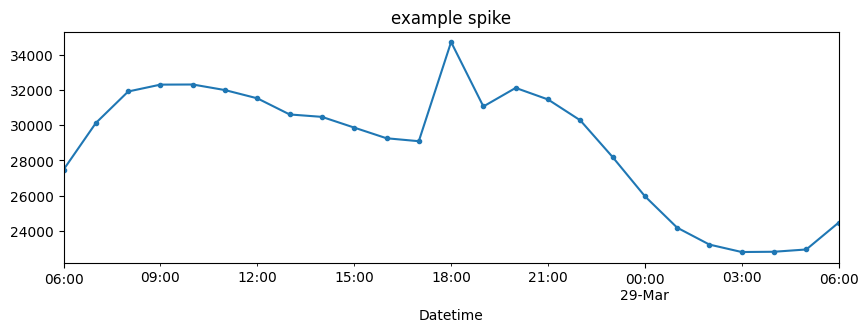

In [5]:
# plot 12 hours before and after the first spike to look at it
t = pjm[spikes].index[0]
# Timedelta("12h") = a time length of 12 hours
pjm[t - pd.Timedelta("12h"): t + pd.Timedelta("12h")].plot(figsize=(10, 3), marker=".")
plt.title("example spike")
plt.savefig("../figures/02_example_spike.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
# delete the spike values and fill them from the neighbours
pjm[spikes] = np.nan
pjm = pjm.interpolate()
# to_frame() changes the series into a table with one column called load
pjm = pjm.to_frame("load")
pjm.head()

,load
Datetime,
2002-01-01 01:00:00,30393.0
2002-01-01 02:00:00,29265.0
2002-01-01 03:00:00,28357.0
2002-01-01 04:00:00,27899.0
2002-01-01 05:00:00,28057.0


##### UCI household

In [7]:
# why: PJM is hourly, so the household data is also made hourly.
# then both datasets can use the same models and the same horizons (1h, 24h, 168h)
# usecols = read only these 3 columns, this saves memory
uci = pd.read_csv("../data/raw/uci_household/household_power_consumption.txt",
                  sep=";", na_values="?", low_memory=False,
                  usecols=["Date", "Time", "Global_active_power"])
# join date and time into one datetime and use it as the index
uci.index = pd.to_datetime(uci["Date"] + " " + uci["Time"], format="%d/%m/%Y %H:%M:%S")
uci = uci["Global_active_power"]

# hourly mean in kW, hours with no readings at all become NaN
# resample("h").mean() = average of the 60 minute values in each hour
uci = uci.resample("h").mean()
print(uci.shape)
print("missing hours:", uci.isna().sum())

(34589,)
missing hours: 421


In [8]:
# length of each gap
# 1 where the hour is missing, 0 where it is not
gaps = uci.isna().astype(int)
# give every block of hours its own number, then add up the 1s = length of each gap.
# e.g. 0 0 1 1 1 0 -> one gap of 3 hours
gap_len = gaps.groupby((gaps != gaps.shift()).cumsum()).sum()
# show only the gaps, from shortest to longest
gap_len[gap_len > 0].sort_values().values

array([  1,  14,  33,  52,  54,  61,  87, 119])

Short gaps (up to 3 hours) -> linear interpolation (for longer gaps this also fills the first 3 hours).
Longer gaps (some are several days) -> average value for the same weekday and hour,
using the train period only.

In [9]:
# why: the models can't train on empty values. short gaps are filled from the neighbours,
# long gaps from the normal value of that weekday and hour, so the daily shape is kept
# fill only gaps of up to 3 hours from the neighbours. limit_area="inside" = don't fill at the start or end
uci_filled = uci.interpolate(limit=3, limit_area="inside")

# last time stamp of the train part (first 70%)
uci_train_end = uci.index[int(len(uci) * 0.7) - 1]
uci_tr = uci[:uci_train_end]
# profile = average load for each (day of week, hour) in the train part,
# e.g. all Mondays at 08:00 -> one average value
profile = uci_tr.groupby([uci_tr.index.dayofweek, uci_tr.index.hour]).mean()
# the hours that are still empty get the average value for that day and hour
still_missing = uci_filled.isna()
idx = uci_filled[still_missing].index
uci_filled[still_missing] = profile.loc[list(zip(idx.dayofweek, idx.hour))].values

print("missing after fill:", uci_filled.isna().sum())

missing after fill: 0


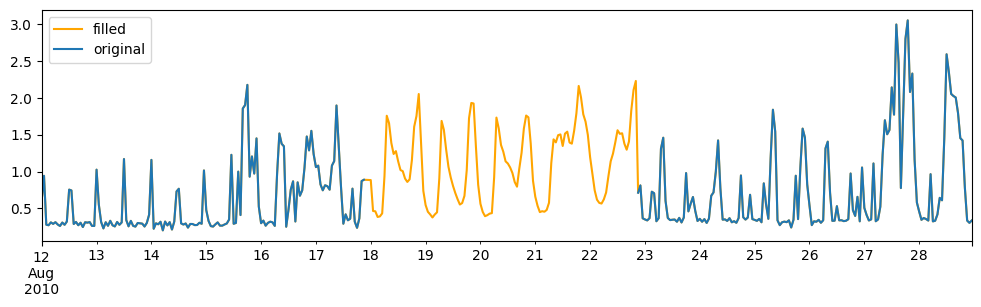

In [10]:
# longest gap is ~5 days in Aug 2010
plt.figure(figsize=(12, 3))
# plot the filled series first and the original on top, so the filled part shows in orange
uci_filled["2010-08-12":"2010-08-28"].plot(label="filled", color="orange")
uci["2010-08-12":"2010-08-28"].plot(label="original")
plt.legend()
plt.savefig("../figures/02_uci_gap_fill.png", dpi=150, bbox_inches="tight")
plt.show()

No spike removal for UCI - in a single house sudden peaks are normal (kettle, oven etc.)

In [11]:
uci = uci_filled.to_frame("load")
# describe() shows count, mean, min, max etc. of the column
uci.describe()

,load
count,34589.000000
mean,1.092183
std,0.893918
min,0.124000
25%,0.343600
50%,0.810067
75%,1.577000
max,6.560533


##### Features

In [12]:
# why: demand depends on the hour, the weekday, the season and holidays.
# these columns give that calendar information to every model
# add_features: adds calendar columns (hour, day, month, weekend, holiday) to the data.
# country is used for the holiday list, e.g. "US" or "FR"
def add_features(df, country):
    # copy() so the original table is not changed
    df = df.copy()
    # take the parts of the date from the index, e.g. 2015-07-04 13:00 -> hour 13, month 7
    df["hour"] = df.index.hour
    df["dayofweek"] = df.index.dayofweek
    df["month"] = df.index.month
    df["dayofyear"] = df.index.dayofyear
    # dayofweek: 0 = Monday ... 6 = Sunday, so 5 and 6 are the weekend. astype(int) changes True/False to 1/0
    df["weekend"] = (df.index.dayofweek >= 5).astype(int)

    # get all public holidays of the country for the years in the data
    hol = holidays.country_holidays(country, years=range(df.index.year.min(), df.index.year.max() + 1))
    # normalize() removes the time (keeps only the date). isin() checks if the date is in the holiday list -> 1 or 0
    df["holiday"] = df.index.normalize().isin(pd.to_datetime(list(hol.keys()))).astype(int)

    # cyclic versions for the neural nets
    # sin and cos put the hour on a circle, so hour 23 and hour 0 are close to each other.
    # with the plain number, 23 and 0 look far apart
    df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
    df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
    # same idea for the month (12 and 1 are close)
    df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
    df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)

    return df

pjm_feat = add_features(pjm, "US")
uci_feat = add_features(uci, "FR")
print(pjm_feat.shape, uci_feat.shape)
pjm_feat.head()

(145392, 11) (34589, 11)


,load,hour,dayofweek,month,dayofyear,weekend,holiday,hour_sin,hour_cos,month_sin,month_cos
Datetime,,,,,,,,,,,
2002-01-01 01:00:00,30393.0,1,1,1,1,0,1,0.258819,0.965926,0.5,0.866025
2002-01-01 02:00:00,29265.0,2,1,1,1,0,1,0.500000,0.866025,0.5,0.866025
2002-01-01 03:00:00,28357.0,3,1,1,1,0,1,0.707107,0.707107,0.5,0.866025
2002-01-01 04:00:00,27899.0,4,1,1,1,0,1,0.866025,0.500000,0.5,0.866025
2002-01-01 05:00:00,28057.0,5,1,1,1,0,1,0.965926,0.258819,0.5,0.866025


In [13]:
print("PJME holiday hours:", pjm_feat["holiday"].sum())
print("UCI holiday hours:", uci_feat["holiday"].sum())

PJME holiday hours: 4391
UCI holiday hours: 1008


##### Split and scale

70 / 15 / 15 in time order, no shuffling. Scaler is fitted on the train part only.

In [14]:
# why: the split is in time order (no shuffle) because in real use we always predict the future from the past.
# val is for tuning, test is only used once at the end
# split: cuts the data into train (70%), val (15%) and test (15%) in time order
def split(df, train=0.7, val=0.15):
    n = len(df)
    # a and b are the row numbers where the data is cut, e.g. 1000 rows -> a = 700, b = 850
    a = int(n * train)
    b = int(n * (train + val))
    # iloc picks rows by position: first a rows, rows a to b, rows after b
    return df.iloc[:a], df.iloc[a:b], df.iloc[b:]

# save: splits the data, saves each part, then scales each part and saves it again
def save(df, name):
    train, val, test = split(df)
    print(name)
    for part, d in [("train", train), ("val", val), ("test", test)]:
        print(f"  {part}: {d.index.min()} -> {d.index.max()}  ({len(d)} rows)")
        # to_parquet() saves the table as a parquet file. it is smaller and faster to read than csv
        # and keeps the dates and number types
        d.to_parquet(f"../data/processed/{name}_{part}.parquet")

    # MinMaxScaler changes every column to the range 0 to 1 with (x - min) / (max - min).
    # e.g. min 10, max 50 -> value 30 becomes 0.5. neural networks train better with small numbers
    scaler = MinMaxScaler()
    # fit() only learns the min and max. we use the train part only, so the test data stays unseen
    scaler.fit(train)
    for part, d in [("train", train), ("val", val), ("test", test)]:
        # transform() does the scaling with the min and max from train.
        # it gives back a plain array, so we put the dates and column names back
        scaled = pd.DataFrame(scaler.transform(d), index=d.index, columns=d.columns)
        scaled.to_parquet(f"../data/processed/{name}_{part}_scaled.parquet")
    # joblib.dump() saves the scaler to a file. later joblib.load() reads it back,
    # so predictions can be changed back to MW / kW
    joblib.dump(scaler, f"../data/processed/{name}_scaler.pkl")

save(pjm_feat, "pjme")
save(uci_feat, "uci")

pjme
  train: 2002-01-01 01:00:00 -> 2013-08-11 14:00:00  (101774 rows)
  val: 2013-08-11 15:00:00 -> 2016-02-06 07:00:00  (21809 rows)
  test: 2016-02-06 08:00:00 -> 2018-08-03 00:00:00  (21809 rows)
uci
  train: 2006-12-16 17:00:00 -> 2009-09-20 12:00:00  (24212 rows)
  val: 2009-09-20 13:00:00 -> 2010-04-24 16:00:00  (5188 rows)
  test: 2010-04-24 17:00:00 -> 2010-11-26 21:00:00  (5189 rows)


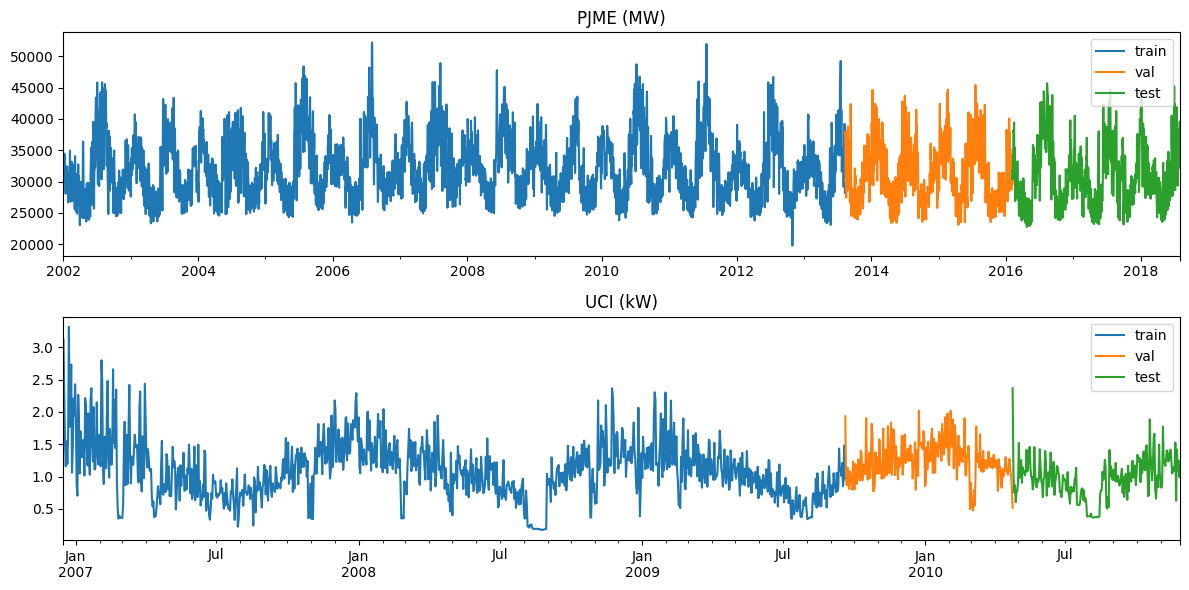

In [15]:
fig, ax = plt.subplots(2, 1, figsize=(12, 6))
for a, df, name in [(ax[0], pjm_feat, "PJME (MW)"), (ax[1], uci_feat, "UCI (kW)")]:
    train, val, test = split(df)
    # daily mean of each part, plotted in the same chart with different colours
    train["load"].resample("D").mean().plot(ax=a, label="train")
    val["load"].resample("D").mean().plot(ax=a, label="val")
    test["load"].resample("D").mean().plot(ax=a, label="test")
    a.set_title(name)
    a.set_xlabel("")
    a.legend()
plt.tight_layout()
plt.savefig("../figures/02_train_val_test_split.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
# list the saved files to check
os.listdir("../data/processed")

['uci_test_scaled.parquet',
 'uci_test.parquet',
 'pjme_test.parquet',
 'uci_train_scaled.parquet',
 'pjme_train.parquet',
 'pjme_test_scaled.parquet',
 '.gitkeep',
 'pjme_scaler.pkl',
 'pjme_val.parquet',
 'uci_scaler.pkl',
 'uci_val.parquet',
 'pjme_train_scaled.parquet',
 'data_inventory.csv',
 'uci_val_scaled.parquet',
 'pattern_summary.csv',
 'pjme_val_scaled.parquet',
 'uci_train.parquet']

Lag / rolling features and sliding windows are not made here. They depend on the forecast horizon
(e.g. lag_24 can't be used for a 168h ahead forecast) so they are built in the model notebooks.